# Credit Scoring Model

CodeAlpha Machine Learning internship, Task 1.

Predict whether a loan applicant is a good (1) or bad (0) credit risk from the German Credit data (1000 customers, 20 features). Models compared: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting. Metrics: precision, recall, F1, ROC-AUC, plus a bank-cost view.

Data: Kaggle dataset *Creditability - German Credit Data* (`german.csv`, `;`-separated). Attach it to the notebook as an input before running.

## 1. Load the data

In [2]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

path = glob.glob("/kaggle/input/**/*.csv", recursive=True)[0]
df = pd.read_csv(path, sep=";")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df["Creditability"].value_counts())
df.head()

Shape: (1000, 21)
Missing values: 0
Creditability
1    700
0    300
Name: count, dtype: int64


,Creditability,Account_Balance,Duration_of_Credit_monthly,Payment_Status_of_Previous_Credit,Purpose,Credit_Amount,Value_Savings_Stocks,Length_of_current_employment,Instalment_per_cent,Sex_Marital_Status,...,Duration_in_Current_address,Most_valuable_available_asset,Age_years,Concurrent_Credits,Type_of_apartment,No_of_Credits_at_this_Bank,Occupation,No_of_dependents,Telephone,Foreign_Worker
0,1,1,18,4,2,1049,1,2,4,2,...,4,2,21,3,1,1,3,1,1,1
1,1,1,9,4,0,2799,1,3,2,3,...,2,1,36,3,1,2,3,2,1,1
2,1,2,12,2,9,841,2,4,2,2,...,4,1,23,3,1,1,2,1,1,1
3,1,1,12,4,0,2122,1,3,3,3,...,2,1,39,3,1,2,2,2,1,2
4,1,1,12,4,0,2171,1,3,4,3,...,4,2,38,1,2,2,2,1,1,2


## 2. Explore the data

int64    21
Name: count, dtype: int64
Unique values per column:
Creditability                          2
Foreign_Worker                         2
No_of_dependents                       2
Telephone                              2
Type_of_apartment                      3
Concurrent_Credits                     3
Guarantors                             3
Instalment_per_cent                    4
Most_valuable_available_asset          4
Account_Balance                        4
Sex_Marital_Status                     4
No_of_Credits_at_this_Bank             4
Occupation                             4
Duration_in_Current_address            4
Length_of_current_employment           5
Payment_Status_of_Previous_Credit      5
Value_Savings_Stocks                   5
Purpose                               10
Duration_of_Credit_monthly            33
Age_years                             53
Credit_Amount                        923


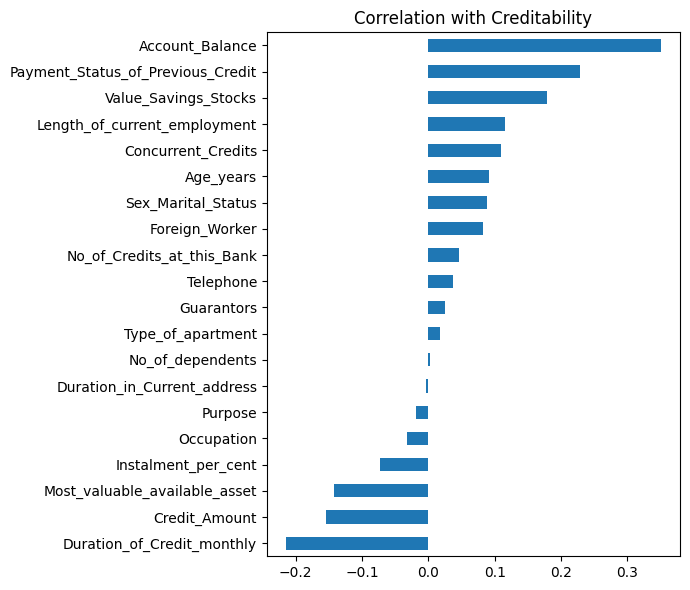

                     mean  count
Account_Balance                 
1                0.507299    274
2                0.609665    269
3                0.777778     63
4                0.883249    394


In [3]:
print(df.dtypes.value_counts())
print("Unique values per column:")
print(df.nunique().sort_values().to_string())

# Correlation of every feature with the target (1 = good, 0 = bad)
corr = df.corr(numeric_only=True)["Creditability"].drop("Creditability").sort_values()
plt.figure(figsize=(7, 6))
corr.plot(kind="barh")
plt.title("Correlation with Creditability")
plt.tight_layout()
plt.show()

# Share of good customers per Account_Balance level
print(df.groupby("Account_Balance")["Creditability"].agg(["mean", "count"]))

## 3. Train/test split and preprocessing (scaling + one-hot)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns="Creditability")
y = df["Creditability"]

num_cols = ["Duration_of_Credit_monthly", "Credit_Amount", "Age_years"]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

print("Train:", X_train.shape, "Test:", X_test.shape)
print(y_train.value_counts(normalize=True).round(2).to_dict())
print(y_test.value_counts(normalize=True).round(2).to_dict())
print("Features after encoding:", preprocess.fit_transform(X_train).shape[1])

Train: (800, 20) Test: (200, 20)
{1: 0.7, 0: 0.3}
{1: 0.7, 0: 0.3}
Features after encoding: 71


## 4. Compare three models with 5-fold cross-validation (training set only)

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
}

scoring = {
    "accuracy": "accuracy",
    "precision_good": "precision",
    "recall_bad": make_scorer(recall_score, pos_label=0),
    "f1_good": "f1",
    "roc_auc": "roc_auc",
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {k.replace("test_", ""): v.mean() for k, v in res.items() if k.startswith("test_")}

pd.DataFrame(rows).T.round(3)

,accuracy,precision_good,recall_bad,f1_good,roc_auc
Logistic Regression,0.698,0.827,0.650,0.767,0.763
Decision Tree,0.660,0.839,0.708,0.724,0.696
Random Forest,0.751,0.762,0.317,0.840,0.775


## 5. The decision-threshold trade-off (out-of-fold, training set only)

In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score

def threshold_table(clf, thresholds):
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    # out-of-fold probability of class 1 (good) for every training customer
    p_good = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    out = []
    for t in thresholds:
        pred = (p_good >= t).astype(int)   # approve only if P(good) >= t
        out.append({
            "threshold": t,
            "recall_bad": recall_score(y_train, pred, pos_label=0),
            "precision_good": precision_score(y_train, pred, pos_label=1),
            "recall_good": recall_score(y_train, pred, pos_label=1),
            "accuracy": (pred == y_train).mean(),
        })
    return pd.DataFrame(out).round(3)

ths = [0.5, 0.6, 0.7, 0.75, 0.8]
print("Random Forest"); print(threshold_table(models["Random Forest"], ths).to_string(index=False))
print("Logistic Regression"); print(threshold_table(models["Logistic Regression"], ths).to_string(index=False))

Random Forest
 threshold  recall_bad  precision_good  recall_good  accuracy
      0.50       0.308           0.760        0.941     0.751
      0.60       0.550           0.811        0.825     0.742
      0.70       0.746           0.860        0.670     0.692
      0.75       0.829           0.889        0.584     0.658
      0.80       0.879           0.895        0.443     0.574
Logistic Regression
 threshold  recall_bad  precision_good  recall_good  accuracy
      0.50       0.650           0.827        0.718     0.698
      0.60       0.767           0.858        0.605     0.654
      0.70       0.871           0.896        0.479     0.596
      0.75       0.892           0.900        0.418     0.560
      0.80       0.921           0.913        0.357     0.526


## 6. First look on the test set (Logistic Regression, threshold 0.6)

Threshold = 0.6  (approve only if P(good) >= 0.6)
              precision    recall  f1-score   support

     bad (0)       0.48      0.85      0.61        60
    good (1)       0.90      0.60      0.72       140

    accuracy                           0.68       200
   macro avg       0.69      0.72      0.67       200
weighted avg       0.78      0.68      0.69       200

ROC-AUC: 0.828


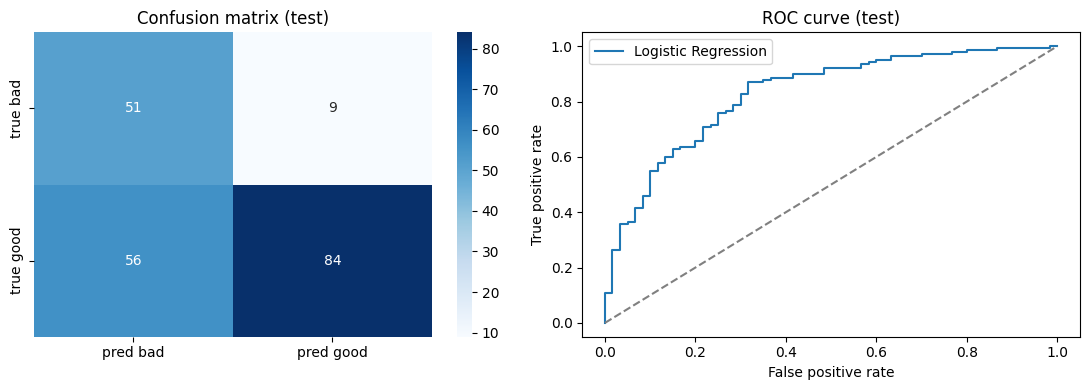

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

THRESHOLD = 0.6
final_model = Pipeline([("prep", preprocess),
                        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
final_model.fit(X_train, y_train)

p_good = final_model.predict_proba(X_test)[:, 1]
pred = (p_good >= THRESHOLD).astype(int)

print(f"Threshold = {THRESHOLD}  (approve only if P(good) >= {THRESHOLD})")
print(classification_report(y_test, pred, target_names=["bad (0)", "good (1)"]))
print("ROC-AUC:", round(roc_auc_score(y_test, p_good), 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["pred bad", "pred good"], yticklabels=["true bad", "true good"])
ax[0].set_title("Confusion matrix (test)")

fpr, tpr, _ = roc_curve(y_test, p_good)
ax[1].plot(fpr, tpr, label="Logistic Regression")
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curve (test)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Compare four algorithms by bank cost (threshold chosen on the training set)

In [8]:
import time
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

# Bank cost (German Credit convention): approving a bad customer costs 5, rejecting a good one costs 1
def bank_cost(y_true, pred):
    fn = ((y_true == 0) & (pred == 1)).sum()   # bad approved
    fp = ((y_true == 1) & (pred == 0)).sum()   # good rejected
    return (5 * fn + fp) / len(y_true)

grid = np.arange(0.2, 0.91, 0.05)
yt = y_train.values
rows = []
for name, clf in candidates.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    # 1) threshold chosen on TRAIN only (out-of-fold) to minimise bank cost
    oof = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    best_t = grid[int(np.argmin([bank_cost(yt, (oof >= t).astype(int)) for t in grid]))]
    # 2) stability of ranking quality across folds
    aucs = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    # 3) final fit + test evaluation
    t0 = time.time(); pipe.fit(X_train, y_train); fit_s = time.time() - t0
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= best_t).astype(int)
    rows.append({
        "model": name,
        "cv_auc": f"{aucs.mean():.3f}+-{aucs.std():.3f}",
        "thr": round(best_t, 2),
        "test_auc": round(roc_auc_score(y_test, p), 3),
        "recall_bad": round(recall_score(y_test, pred, pos_label=0), 3),
        "good_kept": round(recall_score(y_test, pred, pos_label=1), 3),
        "cost/cust": round(bank_cost(y_test.values, pred), 3),
        "fit_s": round(fit_s, 2),
    })

print(pd.DataFrame(rows).to_string(index=False))
print("Baseline cost (approve everyone):", round(bank_cost(y_test.values, np.ones(len(y_test), dtype=int)), 3))

              model       cv_auc  thr  test_auc  recall_bad  good_kept  cost/cust  fit_s
Logistic Regression 0.763+-0.036 0.70     0.828       0.900      0.486      0.510   0.05
      Decision Tree 0.696+-0.039 0.65     0.689       0.750      0.571      0.675   0.02
      Random Forest 0.775+-0.036 0.75     0.827       0.867      0.600      0.480   1.28
  Gradient Boosting 0.763+-0.016 0.90     0.818       0.933      0.300      0.590   0.33
Baseline cost (approve everyone): 1.5


## 8. Final model: Logistic Regression, threshold 0.70 (test metrics, key features, saved files)

In [9]:
import joblib, json

THRESHOLD = 0.70   # chosen on the training set (out-of-fold) to minimise bank cost
p_good = final_model.predict_proba(X_test)[:, 1]
pred = (p_good >= THRESHOLD).astype(int)
print(classification_report(y_test, pred, target_names=["bad (0)", "good (1)"]))
print("Confusion matrix [[bad->bad, bad->good],[good->bad, good->good]]:")
print(confusion_matrix(y_test, pred))
print("ROC-AUC:", round(roc_auc_score(y_test, p_good), 3), "| bank cost/customer:", round(bank_cost(y_test.values, pred), 3))

# Most influential features (coefficients of the logistic regression)
names = final_model.named_steps["prep"].get_feature_names_out()
coef = pd.Series(final_model.named_steps["clf"].coef_[0], index=names).sort_values()
print("\nPush towards BAD:");  print(coef.head(8).round(2).to_string())
print("\nPush towards GOOD:"); print(coef.tail(8).round(2).to_string())

joblib.dump(final_model, "credit_model.joblib")
json.dump({"threshold": THRESHOLD}, open("threshold.json", "w"))
print("\nSaved credit_model.joblib and threshold.json")

              precision    recall  f1-score   support

     bad (0)       0.43      0.90      0.58        60
    good (1)       0.92      0.49      0.64       140

    accuracy                           0.61       200
   macro avg       0.67      0.69      0.61       200
weighted avg       0.77      0.61      0.62       200

Confusion matrix [[bad->bad, bad->good],[good->bad, good->good]]:
[[54  6]
 [72 68]]
ROC-AUC: 0.828 | bank cost/customer: 0.51

Push towards BAD:
cat__Foreign_Worker_1                      -0.79
cat__Account_Balance_1                     -0.78
cat__Purpose_0                             -0.72
cat__Payment_Status_of_Previous_Credit_1   -0.65
cat__Value_Savings_Stocks_1                -0.65
cat__Purpose_6                             -0.61
cat__Sex_Marital_Status_1                  -0.51
cat__Payment_Status_of_Previous_Credit_0   -0.49

Push towards GOOD:
cat__Guarantors_3                           0.52
cat__Purpose_8                              0.61
cat__Length_of_cu